<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js4/TG4_TP_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum**

## **1. Tugas K-Means**

Buatlah sebuah model K-Means dengan ketentuan,

1. Gunakan data 'Mall_Customers.csv'

2. Tentukan fitur apa yang tepat untuk melakukan clustering (minimal 2)

3. Buatlah model K-Means dengan mempertimbangkan jumlah
k yang terbaik.

### **Langkah 1 - Upload & load data**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()
dpath = list(uploaded.keys())[0]

Saving Mall_Customers.csv to Mall_Customers.csv


In [5]:
df = pd.read_csv(dpath)
print("Ukuran data:", df.shape)

Ukuran data: (200, 5)


In [6]:
display(df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


### **Langkah 2 - Pilih fitur clustering**

In [10]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
display(X.head())

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


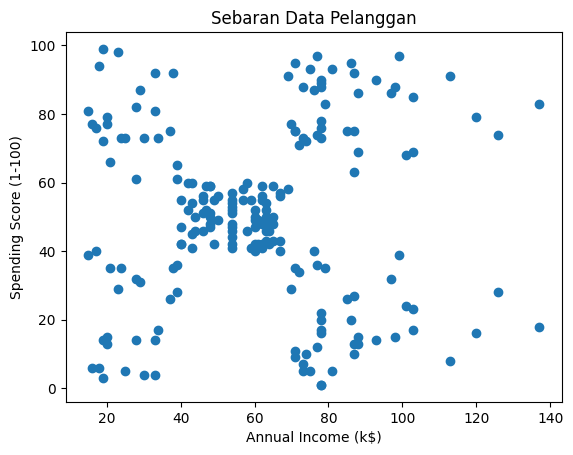

In [11]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Sebaran Data Pelanggan')
plt.show()

### **Langkah 3 - Standarisasi fitur**

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### **Langkah 4 - Tentukan jumlah k terbaik (Elbow & Silhouette)**

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2, 11)
inertia = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lbl = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, lbl))
    print(f"k={k} | inertia={km.inertia_:.2f} | silhouette={sil_scores[-1]:.3f}")

k=2 | inertia=269.69 | silhouette=0.321
k=3 | inertia=157.70 | silhouette=0.467
k=4 | inertia=108.92 | silhouette=0.494
k=5 | inertia=65.57 | silhouette=0.555
k=6 | inertia=55.06 | silhouette=0.540
k=7 | inertia=44.86 | silhouette=0.528
k=8 | inertia=37.23 | silhouette=0.455
k=9 | inertia=32.39 | silhouette=0.457
k=10 | inertia=29.98 | silhouette=0.443


Text(0, 0.5, 'Inertia')

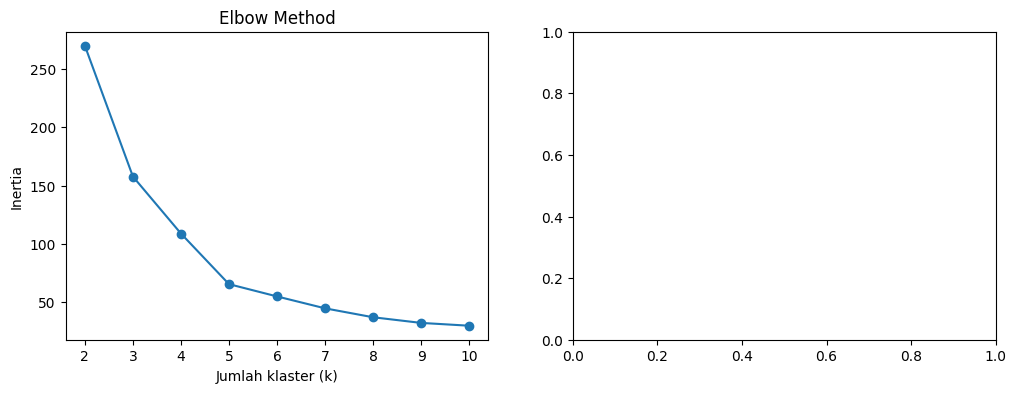

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_range, inertia, 'o-')
ax[0].set_title('Elbow Method')
ax[0].set_xlabel('Jumlah klaster (k)')
ax[0].set_ylabel('Inertia')

In [15]:
ax[1].plot(k_range, sil_scores, 'o-', color='green')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Jumlah klaster (k)')
ax[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [16]:
best_k = list(k_range)[int(np.argmax(sil_scores))]
print("k terbaik berdasarkan silhouette:", best_k)

k terbaik berdasarkan silhouette: 5


### **Langkah 5 - Buat model K-Means final**

In [18]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Silhouette:", round(silhouette_score(X_scaled, df['Cluster']), 3))

Silhouette: 0.555


In [19]:
print(df['Cluster'].value_counts().sort_index())

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [20]:
display(df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


### **Langkah 6 - Visualisasi hasil klaster**

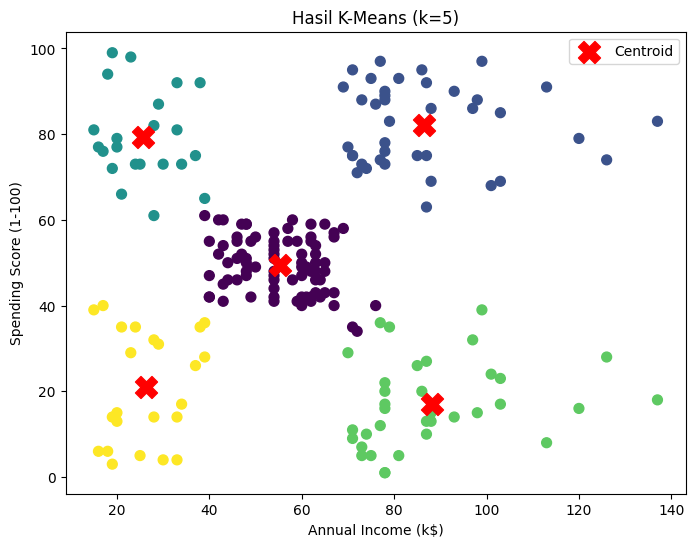

In [22]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df['Cluster'], cmap='viridis', s=50)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=250, label='Centroid')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title(f'Hasil K-Means (k={best_k})')
plt.legend()
plt.show()

In [23]:
display(df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1))

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


## **2. Tugas DBSCAN**


1. Buat dataset make_moons (1000 sampel, noise=0.05), lalu normalisasi.

2. Jalankan DBSCAN dengan eps=0.2, min_samples=5, hitung jumlah klaster & noise.

3. Evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette.

4. Visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam).

5. Lakukan eksperimen:

* eps = 0.05, 0.1, 0.3, 0.5

* min_samples = 3, 10, 20

* Catat perubahan klaster, noise, dan kualitas evaluasi.

### **Langkah 1 - Dataset make_moons + normalisasi**

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

In [25]:
X, labels_true = make_moons(n_samples=1000, noise=0.05, random_state=0)
X = StandardScaler().fit_transform(X)

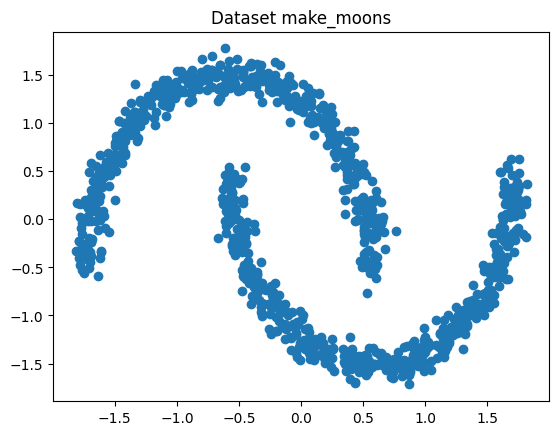

In [26]:
plt.scatter(X[:, 0], X[:, 1])
plt.title('Dataset make_moons')
plt.show()

### **Langkah 2 - Jalankan DBSCAN (eps=0.2, min_samples=5)**

In [27]:
from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.2, min_samples=5).fit(X)
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 2
Estimated number of noise points: 0


### **Langkah 3 - Evaluasi**

In [28]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.392


### **Langkah 4 - Visualisasi hasil**

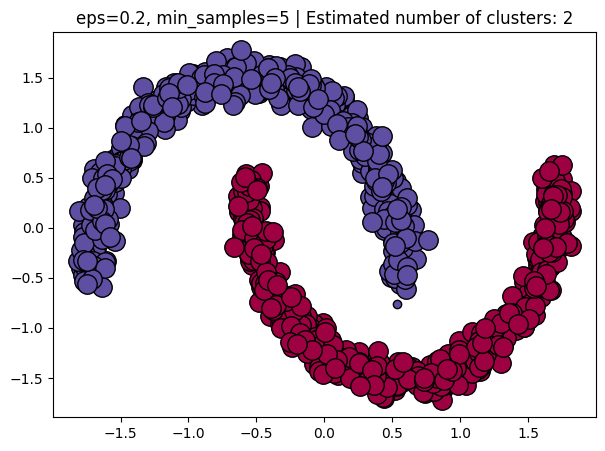

In [29]:
def plot_dbscan(X, db, title=""):
    labels = db.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    unique_labels = set(labels)
    core_samples_mask = np.zeros_like(labels, dtype=bool)
    core_samples_mask[db.core_sample_indices_] = True

    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # noise = hitam

        class_member_mask = labels == k

        xy = X[class_member_mask & core_samples_mask]
        plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col),
                 markeredgecolor="k", markersize=14)

        xy = X[class_member_mask & ~core_samples_mask]
        plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col),
                 markeredgecolor="k", markersize=6)

    plt.title(f"{title} | Estimated number of clusters: {n_clusters}")

plt.figure(figsize=(7, 5))
plot_dbscan(X, db, "eps=0.2, min_samples=5")
plt.show()

### **Langkah 5 - Eksperimen eps dan min_samples**

In [30]:
import pandas as pd

eps_list = [0.05, 0.1, 0.3, 0.5]
min_samples_list = [3, 10, 20]

hasil = []
for eps in eps_list:
    for ms in min_samples_list:
        model = DBSCAN(eps=eps, min_samples=ms).fit(X)
        lbl = model.labels_

        n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_ns = list(lbl).count(-1)

        # silhouette hanya valid jika ada minimal 2 label unik
        if 2 <= len(set(lbl)) <= len(X) - 1:
            sil = metrics.silhouette_score(X, lbl)
        else:
            sil = np.nan

        hasil.append({
            'eps': eps,
            'min_samples': ms,
            'n_klaster': n_cl,
            'n_noise': n_ns,
            'Homogeneity': metrics.homogeneity_score(labels_true, lbl),
            'Completeness': metrics.completeness_score(labels_true, lbl),
            'V-measure': metrics.v_measure_score(labels_true, lbl),
            'ARI': metrics.adjusted_rand_score(labels_true, lbl),
            'AMI': metrics.adjusted_mutual_info_score(labels_true, lbl),
            'Silhouette': sil
        })

df_hasil = pd.DataFrame(hasil).round(3)
display(df_hasil)

,eps,min_samples,n_klaster,n_noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,67,197,0.804,0.155,0.260,0.033,0.246,0.078
1,0.05,10,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
2,0.05,20,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
3,0.10,3,3,18,0.983,0.708,0.824,0.854,0.823,0.138
4,0.10,10,9,63,0.939,0.358,0.519,0.435,0.517,0.184
5,0.10,20,6,844,0.157,0.153,0.155,0.010,0.152,-0.409
6,0.30,3,2,0,1.000,1.000,1.000,1.000,1.000,0.392
7,0.30,10,2,0,1.000,1.000,1.000,1.000,1.000,0.392
8,0.30,20,2,0,1.000,1.000,1.000,1.000,1.000,0.392
9,0.50,3,1,0,0.000,1.000,0.000,0.000,0.000,NaN


### **Langkah 6 - Visualisasi semua kombinasi**

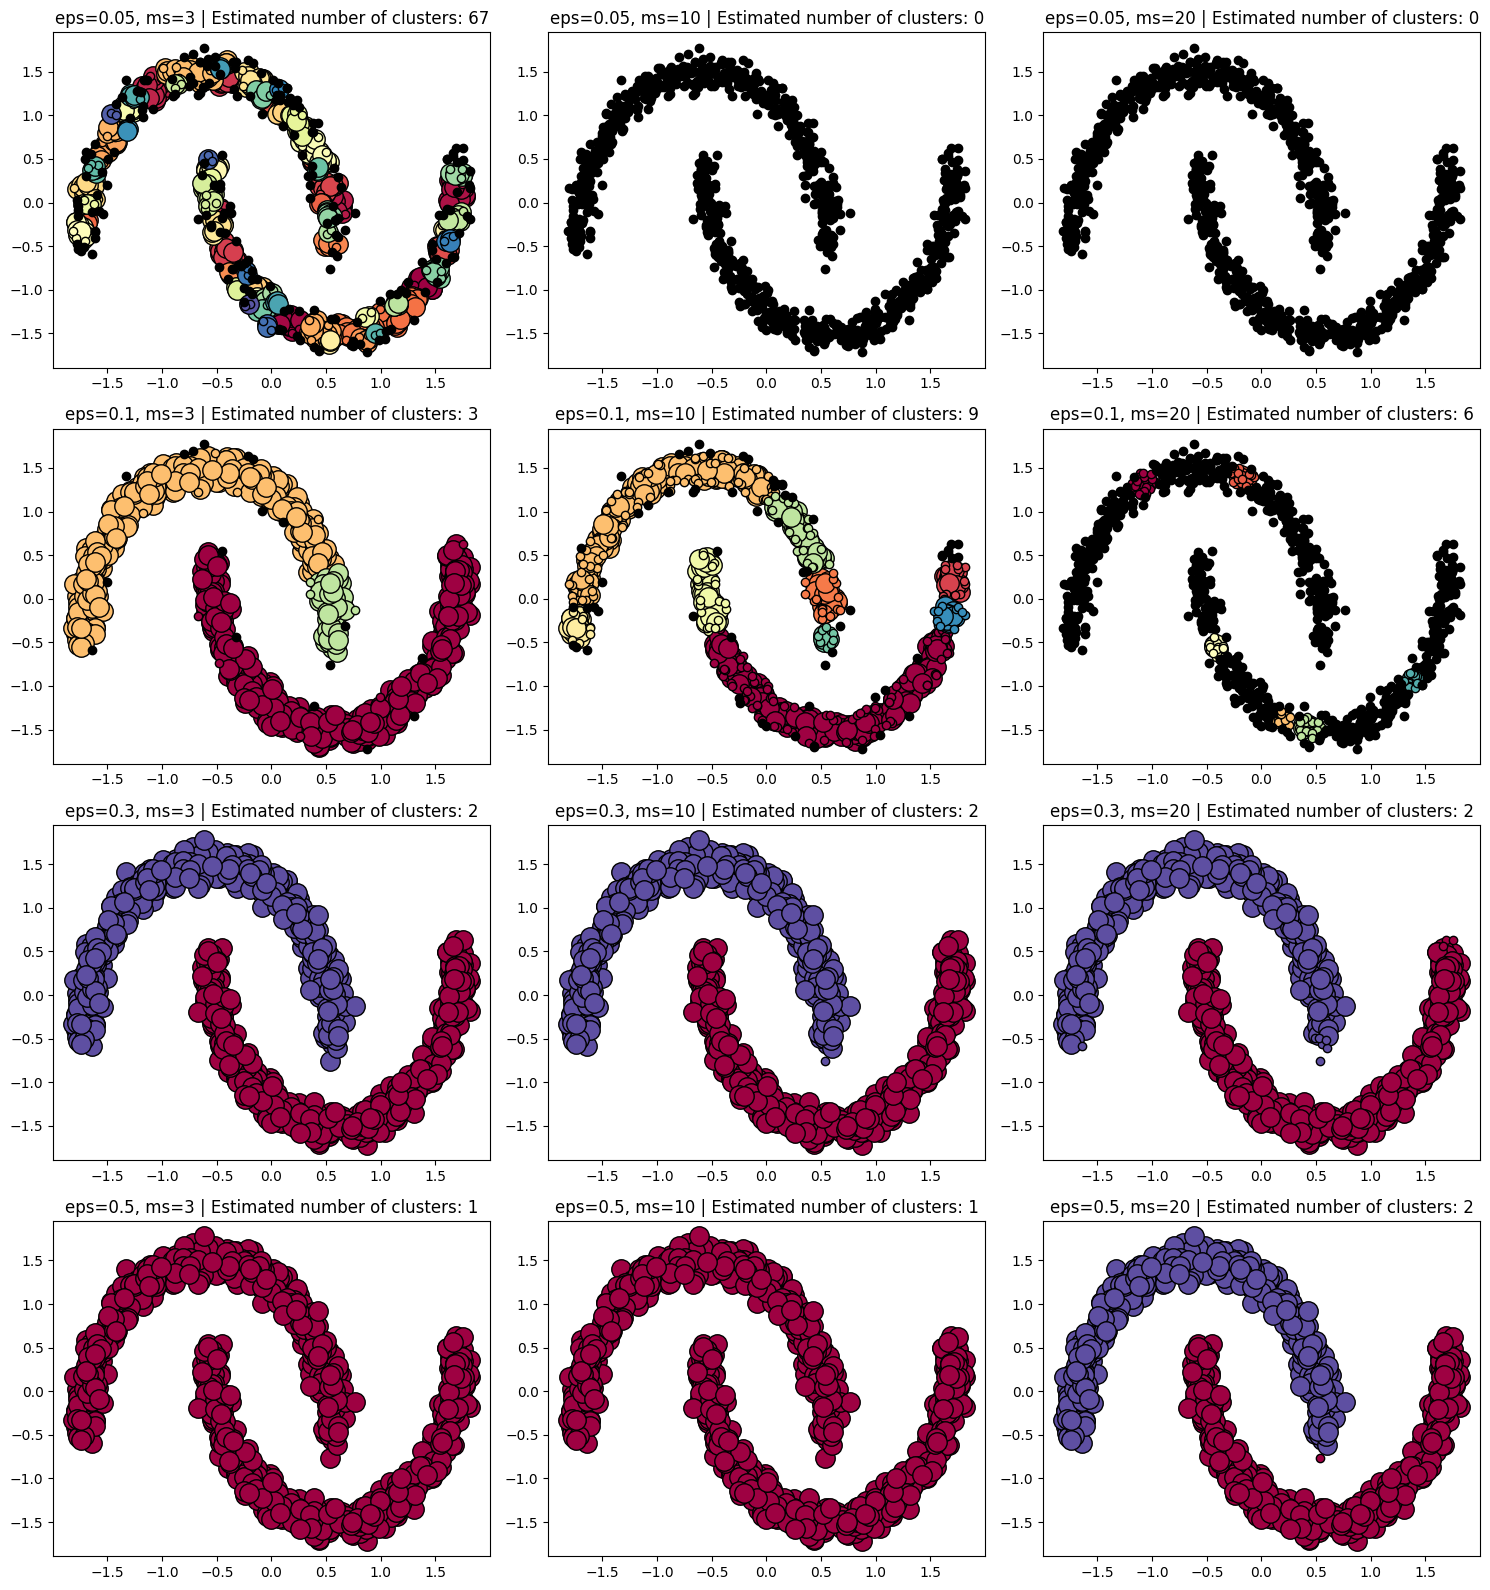

In [31]:
fig, axes = plt.subplots(len(eps_list), len(min_samples_list), figsize=(15, 16))

for i, eps in enumerate(eps_list):
    for j, ms in enumerate(min_samples_list):
        plt.sca(axes[i, j])
        model = DBSCAN(eps=eps, min_samples=ms).fit(X)
        plot_dbscan(X, model, f"eps={eps}, ms={ms}")

plt.tight_layout()
plt.show()